# E01 — A secondary substation and its low-voltage network

This case study computes the earthing of a 10/0.4 kV secondary substation
(German *Ortsnetzstation*) together with the TN low-voltage network it
feeds: 30 single-family houses whose foundation earth electrodes are bonded
to the station earth through the PEN conductors, in two-layer soil. It is
written for grounding engineers who want numbers, and it answers five
questions:

1. How much does the low-voltage network lower the earthing impedance at
   the station (the *global earthing* effect), and how does that depend on
   the number of houses and on the soil?
2. What earth potential rise and which touch voltages does an earth fault
   on the medium-voltage side of the station cause, with and without the
   network?
3. Which potentials does the PEN transfer to the houses, and where in the
   network is the touch voltage largest?
4. What changes at 1 kHz?
5. How far can the numbers be trusted?

The building blocks are explained in the tutorials and are not repeated
here: [T03](../tutorials/T03_interconnected_systems_and_impedances.ipynb)
(input, cluster and electrode impedance, split factor),
[T06](../tutorials/T06_tn_network_synthetic_and_osm.ipynb) (the network
generator), [T04](../tutorials/T04_frequency_response_and_rho_f.ipynb)
(frequency response) and
[T08](../tutorials/T08_touch_and_step_assessment.ipynb) (touch voltages
and EN 50522). The network is one point of the parameter space of the AP1
studies (see the [glossary](../reference/glossary.md)) for which the
generators were built: a station, house connections and cable cabinets in
two-layer soil.

Runtime: about 70 s.

In [1]:
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf
from groundfield.generators import (
    HomogeneousSoilSpec,
    PenConfig,
    TnNetworkConfig,
    TnNetworkGenerator,
    TwoLayerSoilSpec,
)

print("groundfield", gf.__version__)

groundfield 2026.11.0


## The model

| Part | Model | Generator setting |
|---|---|---|
| station earth | ring of 4 m radius, 0.6 m deep; four 2.5 m rods on a 2 m circle; bonded | `SubstationConfig` default |
| houses | 30 foundation earth electrodes, 10 m × 10 m, 2 × 2 meshes, 0.8 m deep, bare | `residential` default |
| layout | three rows of ten houses, 25 m apart, rows 30 m apart; the station in the centre | `ManhattanGridPlacement` default |
| cable cabinets | two, at the far ends of the two halves, one 1.5 m rod each | `CabinetConfig` default |
| PEN | copper, 78.5 mm², insulated, 0.6 m deep, inductive | `PenConfig(inductance_model="neumann")` |
| soil | $\rho_1$ = 200 Ω·m, $h_1$ = 5 m, over $\rho_2$ = 30 Ω·m | `TwoLayerSoilSpec` |

**Station.** The HV protective earth and the LV system earth of the
station form one common earthing system, as usual in TN networks. The LV
neutral, and with it the PEN of every outgoing cable, is bonded to the
station earth.

**Network.** Each of the two cable cabinets (German *KVS*) has a PEN main of
its own from the station (star topology). The mains run along the centre
row and are joined to its houses; the houses of the outer rows are
connected to the main of their half by service drops. The foundations are
modelled bare; the effect of their concrete encasement is the topic of
case study E02.

**PEN.** A wire of 5 mm radius, insulated from the soil (no leakage), cut
into 5 m pieces. The pieces carry their self and mutual inductances
(Neumann's formula) and the earth-return correction of the conducting soil
(`sommerfeld`, the default). The inductance makes the network frequency
dependent.

**Soil.** A resistive top layer (dry sand) over a conductive bottom
(water-bearing ground). It is one of the soils of the AP1 study grid, in
which $\rho_1$ runs from 30 to 1000 Ω·m, $\rho_2$ from 30 to 200 Ω·m and
$h_1$ from 5 to 30 m; section 1 varies it.

**Fault.** An earth fault on the MV side of the station drives a current
$I_E$ into the station earth, which returns through remote earth to the
infeeding substation. The model feeds 1 A into the station cluster. The
field problem is linear, so every voltage is first given per ampere of
$I_E$ (in V/A, numerically an impedance) and scaled in section 2.

**Engines.** Two-layer soil and wire electrodes call for the default
`image` engine, which forwards to `image_2layer`: closed-form kernels,
cheap, and accurate for impedances. Its current model, one uniform current
per straight wire, is not accurate enough for surface potentials next to
meshes and bonded clusters (T08), and both the foundations and the station
are such clusters. For touch voltages the network is therefore solved a
second time with `mom`, which carries one current per segment. Both use
1 m segments; section 5 checks that choice.

In [2]:
SOIL = TwoLayerSoilSpec(rho_1=200.0, rho_2=30.0, h_1=5.0)


def network(n_houses=30, soil=SOIL):
    # The generator's TN network with an inductive PEN.
    config = TnNetworkConfig(
        soil=soil,
        building_counts={"residential": n_houses},
        pen=PenConfig(inductance_model="neumann"),
    )
    return TnNetworkGenerator(config, seed=1).build()


def station_alone(soil=SOIL):
    # The same station earth without any connection to the LV network.
    alone = gf.create_world(soil=soil.to_soil(np.random.default_rng(0)))
    grounding = TnNetworkConfig().substation.grounding
    anchor = grounding.build_at(alone, (0.0, 0.0), "trafo", np.random.default_rng(0))
    gf.create_source(alone, attached_to=anchor, magnitude=1.0)
    return alone


world = network()
STATION = world.sources[0].attached_to
HOUSES = [e.name for e in world.electrodes if e.name.endswith("_foundation_0")]
pen = [c for c in world.conductors if c.conductor_type == "pen"]
print(
    f"{len(world.electrodes)} electrode wires, {len(HOUSES)} houses, source into {STATION!r}"
)
print(f"{len(pen)} PEN sections, {sum(c.length for c in pen):.0f} m of PEN in all")

187 electrode wires, 30 houses, source into 'trafo_ring_0'
32 PEN sections, 729 m of PEN in all


One house is added by hand: an old building at the eastern end of the
network, 11.5 m beyond the eastern cable cabinet, **without** an earth
electrode of its own. Its PEN ends on a junction at the service connection
box, a node without contact to the soil. No current flows to it, so it
changes nothing else in the solution; sections 2 and 3 use it.

diagnose: no findings


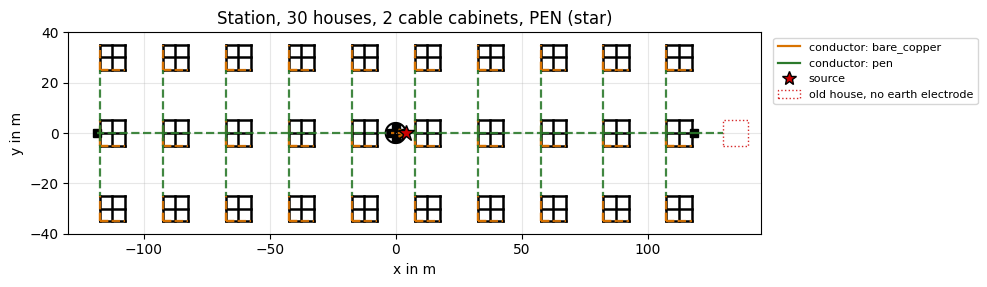

In [3]:
OLD_HOUSE = [(130.0, -5.0), (140.0, -5.0), (140.0, 5.0), (130.0, 5.0)]  # outline in m
OLD_BOX = (130.0, 0.0)  # service connection box on the west wall
gf.create_junction(world, name="old_house_box", position=(*OLD_BOX, 0.6))
gf.create_conductor(
    world,
    name="pen_old_house",
    start="kvs_1_rod_0",
    end="old_house_box",
    conductor_type="pen",
    cross_section="from_radius",
    discretize_segment_length=5.0,
    inductance_model="neumann",
)
print("diagnose:", gf.diagnose(world))

fig = gf.plot_world(
    world, figsize=(10, 3.6), title="Station, 30 houses, 2 cable cabinets, PEN (star)"
)
ax = fig.axes[0]
(outline,) = ax.fill(*np.transpose(OLD_HOUSE), fill=False, ls=":", color="tab:red")
legend = ax.get_legend()
handles = [*legend.legend_handles, outline]
labels = [*(t.get_text() for t in legend.get_texts()), "old house, no earth electrode"]
ax.legend(handles, labels, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
ax.set_xlim(-130.0, 145.0)
fig.tight_layout()

## 1 How much does the network lower the station's earthing impedance?

Two numbers describe the global earthing effect:

- the resistance $R_\mathrm{station}$ of the station earth **alone**, the
  value a planner computes for the station without its LV connections;
- the **input impedance** $Z_\mathrm{in}$ of the network seen from the
  station, the impedance the fault current meets: the station, every house
  and both cabinets in parallel through the PEN.

The **split factor** $s$ is the share of $I_E$ that leaves the soil through
the station's own electrodes (T03).

In [4]:
FREQUENCIES = [0.0, 50.0, 150.0, 250.0, 350.0, 550.0, 750.0, 1000.0]
F50, F1K = FREQUENCIES.index(50.0), FREQUENCIES.index(1000.0)
engine = gf.create_engine(segment_length=1.0, frequencies=FREQUENCIES)

alone = station_alone()
result = engine.solve(world)
result_alone = engine.solve(alone)

r_alone = result_alone.input_impedance()[F50].real
z_in = np.array(result.input_impedance())
s = [gf.split_factor(result, world, frequency_index=k) for k in range(len(FREQUENCIES))]
print(f"station earth alone:        R_station = {r_alone:.3f} Ohm")
print(f"station with the network:   Z_in      = {z_in[F50]:.4f} Ohm at 50 Hz")
print(f"ratio |Z_in| / R_station:   {abs(z_in[F50]) / r_alone:.2%}")
print(f"split factor of the station: |s| = {abs(s[F50]):.2%}")

share = {"station": 0.0, "houses": 0.0, "cabinets": 0.0}
for name, current in result.electrode_currents.items():
    site = "station" if name.startswith("trafo") else "houses"
    site = "cabinets" if name.startswith("kvs") else site
    share[site] += current[F50]
for site, current in share.items():
    print(f"  of 1 A, into the soil at the {site:8s}: {abs(current):.4f} A")

station earth alone:        R_station = 9.901 Ohm
station with the network:   Z_in      = 0.2906+0.0111j Ohm at 50 Hz
ratio |Z_in| / R_station:   2.94%
split factor of the station: |s| = 1.75%
  of 1 A, into the soil at the station : 0.0175 A
  of 1 A, into the soil at the houses  : 0.9804 A
  of 1 A, into the soil at the cabinets: 0.0021 A


In [5]:
# Kirchhoff: all of I_E leaves through the soil
assert abs(sum(share.values()) - 1.0) < 1e-9
assert abs(share["station"] - s[F50]) < 1e-9  # the station's share is the split factor
assert abs(z_in[F50]) < 0.05 * r_alone  # the network takes over the earthing
assert abs(share["houses"]) > 0.95

The station earth alone has about 9.9 Ω. Connected to the network, the
fault current meets 0.29 Ω, 2.9 % of that: the network lowers the
impedance by a factor of 34. Only 1.75 % of $I_E$ leaves the soil at the
station's own electrodes, 98 % at the houses. The PEN puts the station and
the 30 foundations in parallel; together they cover about 240 m × 70 m,
and at that size the current reaches the conductive bottom layer (the
soil comparison below shows it).

This is the mechanism behind a *global earthing system* in the sense of
EN 50522. Whether a real network qualifies as one is a separate assessment
that this example does not make.

### How many houses does it take?

The generator builds the same network with 1, 5, 10, 30 and 80 houses
(the smaller ones in one row through the station, the larger ones in rows
of ten); each is solved at 50 Hz and at 1 kHz.

  1 houses: |Z_in| = 3.9385 Ohm at 50 Hz, 4.0244 Ohm at 1 kHz (39.78% / 40.65% of the station alone)
  5 houses: |Z_in| = 1.2870 Ohm at 50 Hz, 1.4018 Ohm at 1 kHz (13.00% / 14.16% of the station alone)
 10 houses: |Z_in| = 0.7077 Ohm at 50 Hz, 0.7527 Ohm at 1 kHz ( 7.15% /  7.60% of the station alone)
 30 houses: |Z_in| = 0.2908 Ohm at 50 Hz, 0.3961 Ohm at 1 kHz ( 2.94% /  4.00% of the station alone)
 80 houses: |Z_in| = 0.1358 Ohm at 50 Hz, 0.2469 Ohm at 1 kHz ( 1.37% /  2.49% of the station alone)


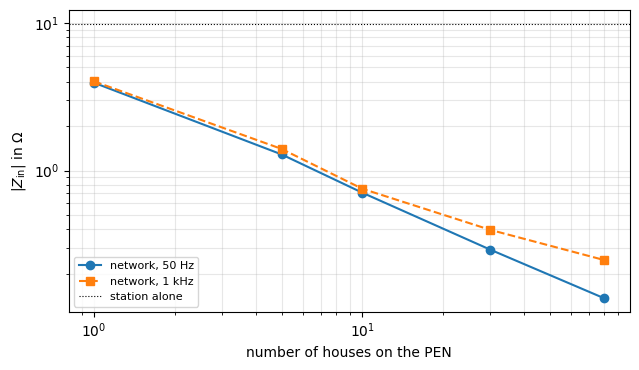

In [6]:
counts = [1, 5, 10, 30, 80]
sweep_engine = gf.create_engine(segment_length=1.0, frequencies=[50.0, 1000.0])
z_count = np.array([sweep_engine.solve(network(n)).input_impedance() for n in counts])
for n, (z_50, z_1k) in zip(counts, z_count, strict=True):
    print(
        f"{n:3d} houses: |Z_in| = {abs(z_50):.4f} Ohm at 50 Hz, {abs(z_1k):.4f} Ohm at 1 kHz "
        f"({abs(z_50) / r_alone:6.2%} / {abs(z_1k) / r_alone:6.2%} of the station alone)"
    )

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.loglog(counts, np.abs(z_count[:, 0]), "o-", label="network, 50 Hz")
ax.loglog(counts, np.abs(z_count[:, 1]), "s--", label="network, 1 kHz")
ax.axhline(r_alone, color="k", lw=0.8, ls=":", label="station alone")
ax.set_xlabel("number of houses on the PEN")
ax.set_ylabel(r"$|Z_\mathrm{in}|$ in $\Omega$")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

In [7]:
assert np.all(np.diff(np.abs(z_count[:, 0])) < 0)  # every house lowers Z_in at 50 Hz
assert np.all(np.abs(z_count[:, 1]) > np.abs(z_count[:, 0]))  # higher at 1 kHz
assert abs(z_count[3, 0] / z_in[F50] - 1.0) < 1e-9  # 30 houses: the network above
assert abs(z_count[4, 0] / z_count[3, 0]) > 30 / 80  # slower than 1/n

A single house on the PEN already lowers the impedance to 40 % of the
station alone, five houses to 13 %, thirty to 2.9 %. Each further house
helps less, because it stands in the potential funnels of the others:
from 30 to 80 houses $\lvert Z_\mathrm{in}\rvert$ falls to 47 % of its value, where
$1/n$ would give 38 %. At 1 kHz the curve flattens, because the reactance
of the PEN limits how much the remote houses can help (section 4).

### How much does the soil matter?

The same station and the same 30-house network in five soils of the AP1
grid, at 50 Hz:

In [8]:
soils = {
    "30 over 200 Ohm m, h1 = 5 m": TwoLayerSoilSpec(rho_1=30.0, rho_2=200.0, h_1=5.0),
    "100 Ohm m, homogeneous": HomogeneousSoilSpec(rho=100.0),
    "200 over 30 Ohm m, h1 = 5 m (this case)": SOIL,
    "1000 over 30 Ohm m, h1 = 5 m": TwoLayerSoilSpec(rho_1=1000.0, rho_2=30.0, h_1=5.0),
    "1000 over 200 Ohm m, h1 = 30 m": TwoLayerSoilSpec(
        rho_1=1000.0, rho_2=200.0, h_1=30.0
    ),
}
engine_50 = gf.create_engine(segment_length=1.0, frequencies=[50.0])
ratios = {}
lines = [f"{'soil':40s} {'R_station':>10s} {'|Z_in|':>10s} {'ratio':>6s}"]
for label, soil in soils.items():
    r_st = engine_50.solve(station_alone(soil)).input_impedance()[0].real
    z_nw = abs(engine_50.solve(network(soil=soil)).input_impedance()[0])
    ratios[label] = z_nw / r_st
    lines.append(f"{label:40s} {r_st:6.2f} Ohm {z_nw:6.3f} Ohm {ratios[label]:6.1%}")
print("\n".join(lines))

soil                                      R_station     |Z_in|  ratio
30 over 200 Ohm m, h1 = 5 m                3.17 Ohm  0.457 Ohm  14.4%
100 Ohm m, homogeneous                     6.53 Ohm  0.386 Ohm   5.9%
200 over 30 Ohm m, h1 = 5 m (this case)    9.90 Ohm  0.291 Ohm   2.9%
1000 over 30 Ohm m, h1 = 5 m              46.45 Ohm  1.064 Ohm   2.3%
1000 over 200 Ohm m, h1 = 30 m            62.56 Ohm  2.363 Ohm   3.8%


In [9]:
assert all(0.0 < q < 0.2 for q in ratios.values())  # the network helps in every soil
# the least reduction: a conductive top over a resistive bottom
assert max(ratios, key=ratios.get).startswith("30 over 200")

In every soil the network carries the fault current: its impedance is
2.3 to 14 % of the station alone. The two impedances see different soil.
The station's electrodes, all within 2.5 m of the surface, see mainly the
top layer; the network, some 240 m wide, sees mainly the bottom layer.
The network impedance therefore follows $\rho_2$ (0.29 Ω over 30 Ω·m,
0.46 Ω over 200 Ω·m, both with a 5 m top layer), and the reduction is
largest for a resistive top over a conductive bottom and smallest the
other way round. A thick resistive top layer (1000 Ω·m, 30 m) keeps the
network at 2.4 Ω.

## 2 Earth potential rise and touch voltages during an MV earth fault

The **earth potential rise** (EPR) $U_E = \lvert Z_\mathrm{in}\rvert\,I_E$ is the
potential of the station earth against remote earth. A person who touches
an accessible metal part bonded to an earth electrode and stands 1 m from
it bridges the **touch voltage** $U_T = \varphi_\mathrm{part} -
\varphi_\mathrm{feet}$ (the prospective value, see T08). The touch points:

- the **station housing**, 3 m × 2.5 m in the centre of the ring: feet 1 m
  from the middle of each wall, all round, none inside the housing;
- the **houses** with a foundation earth electrode: metal parts on the
  outer walls (a service connection box, a tap, a gate), feet 1 m outside
  the foundation in 24 directions around each house
  (`touch_voltage_envelope`);
- the **old house**: its service connection box, feet 1 m around it, none
  inside the house.

They are evaluated on the `mom` solution, which is field-grade next to the
foundations.

In [10]:
field_engine = gf.create_engine(
    backend="mom", segment_length=1.0, frequencies=FREQUENCIES
)
field = field_engine.solve(world)
field_alone = field_engine.solve(alone)

# the station housing, 3 m x 2.5 m: its outline and the middle of each wall in m
HOUSING = [(-1.5, -1.25), (1.5, -1.25), (1.5, 1.25), (-1.5, 1.25)]
WALLS = [(1.5, 0.0), (0.0, 1.25), (-1.5, 0.0), (0.0, -1.25)]


def touch_station(res, wld, k=F50):
    # Largest |U_T| in V/A at the walls of the station housing.
    u = [
        gf.touch_voltage_at_part(
            res,
            wld,
            position=p,
            bonded_to=STATION,
            exclude=[HOUSING],
            frequency_index=k,
        )[1]
        for p in WALLS
    ]
    return np.abs(np.concatenate(u)).max()


def touch_houses(res, wld, k=F50):
    # Largest |U_T| in V/A 1 m outside each foundation, one value per house.
    largest = []
    for h in HOUSES:
        _, u = gf.touch_voltage_envelope(res, wld, electrode=h, frequency_index=k)
        largest.append(np.abs(u).max())
    return np.array(largest)


def touch_old_house(res, wld, k=F50):
    # Largest |U_T| in V/A around the service connection box of the old house.
    u = gf.touch_voltage_at_part(
        res,
        wld,
        position=OLD_BOX,
        bonded_to="old_house_box",
        exclude=[OLD_HOUSE],
        frequency_index=k,
    )[1]
    return np.abs(u).max()


# per ampere of I_E at 50 Hz: EPR, U_T at the station, the houses, the old house (V/A)
per_ampere = {
    "station alone": (
        abs(field_alone.electrode_potentials[STATION][F50]),
        touch_station(field_alone, alone),
        np.nan,
        np.nan,
    ),
    "with the network": (
        abs(field.electrode_potentials[STATION][F50]),
        touch_station(field, world),
        touch_houses(field, world).max(),
        touch_old_house(field, world),
    ),
}
WIDTHS = (7, 12, 11, 14)
print(
    f"{'per ampere, 50 Hz':18s} {'EPR':>7s} {'U_T station':>12s} {'U_T houses':>11s} {'U_T old house':>14s}"
)
for case, values in per_ampere.items():
    row = [
        f"{v:{w}.4f}" if np.isfinite(v) else f"{'-':>{w}s}"
        for v, w in zip(values, WIDTHS, strict=True)
    ]
    print(f"{case:18s} {' '.join(row)}  V/A")

per ampere, 50 Hz      EPR  U_T station  U_T houses  U_T old house
station alone       9.8176       3.5953           -              -  V/A
with the network    0.2875       0.0650      0.1501         0.2210  V/A


Two fault scenarios show what these per-ampere values mean. $I_E$ is the
part of the earth-fault current that flows into this earthing system; the
share that the screens of the MV cables carry back (the reduction factor)
is not computed by groundfield and is assumed to be taken off already. The
permissible touch voltage $U_{Tp}$ comes from the library's EN 50522 curve
(`gf.permissible_touch_voltage_en50522`).

| Scenario | MV neutral earthing | $I_E$ | fault duration $t_f$ |
|---|---|---|---|
| A | resonant (Petersen coil): residual current, the network keeps running | 60 A | not cleared |
| B | low-impedance, or a double earth fault: cleared by protection | 1000 A | 0.5 s |

The currents are examples, not data of a real network. The last column
below is the largest $I_E$ for which every touch voltage stays within
$U_{Tp}$.

In [11]:
SCENARIOS = {"A": (60.0, math.inf), "B": (1000.0, 0.5)}  # I_E in A, t_f in s
worst, allowed = {}, {}
for key, (i_e, t_f) in SCENARIOS.items():
    u_tp = gf.permissible_touch_voltage_en50522(t_f)
    duration = "not cleared" if math.isinf(t_f) else f"t_f = {t_f} s"
    print(f"scenario {key}: I_E = {i_e:.0f} A, {duration}, U_Tp = {u_tp:.0f} V")
    print(
        f"  {'':16s} {'EPR':>7s} {'U_T station':>11s} {'houses':>7s} {'old house':>9s} {'I_E allowed':>11s}"
    )
    for case, (epr, *u_t) in per_ampere.items():
        worst[key, case] = np.nanmax(u_t) * i_e
        allowed[key, case] = u_tp / np.nanmax(u_t)
        row = [
            f"{u * i_e:{w - 2}.0f} V" if np.isfinite(u) else f"{'-':>{w}s}"
            for u, w in zip(u_t, (11, 7, 9), strict=True)
        ]
        print(
            f"  {case:16s} {epr * i_e:5.0f} V {' '.join(row)} {allowed[key, case]:9.0f} A"
        )

scenario A: I_E = 60 A, not cleared, U_Tp = 80 V
                       EPR U_T station  houses old house I_E allowed
  station alone      589 V       216 V       -         -        22 A
  with the network    17 V         4 V     9 V      13 V       362 A
scenario B: I_E = 1000 A, t_f = 0.5 s, U_Tp = 225 V
                       EPR U_T station  houses old house I_E allowed
  station alone     9818 V      3595 V       -         -        63 A
  with the network   288 V        65 V   150 V     221 V      1018 A


In [12]:
U_TP = {
    key: gf.permissible_touch_voltage_en50522(t_f)
    for key, (_, t_f) in SCENARIOS.items()
}
assert U_TP["A"] == 80.0  # EN 50522: a fault that is not cleared
for key in SCENARIOS:
    assert worst[key, "station alone"] > U_TP[key]  # fails both scenarios
    assert worst[key, "with the network"] <= U_TP[key]  # passes both
assert 0.95 < worst["B", "with the network"] / U_TP["B"] <= 1.0  # B: a narrow margin
assert per_ampere["with the network"][3] > 1.3 * per_ampere["with the network"][2]

Without the network the station earth would rise to 9.8 V per ampere and
expose a person at the housing to 3.6 V/A: in scenario A 216 V against the
permissible 80 V. The station alone tolerates an uncleared fault current of
only 22 A.

With the network the EPR falls to 0.29 V/A, and both scenarios pass. The
station housing, in the middle of its ring and of the network, sees only
0.065 V/A, the houses with a foundation earth electrode at most 0.15 V/A.
The largest touch voltage is no longer at the station but at the old house
without an earth electrode, 0.22 V/A. It sets the limits of the network:
362 A for a fault that is not cleared, 1018 A for one cleared in 0.5 s. In
scenario B it reaches 221 V against 225 V, a margin of 2 %, smaller than
the spread between the engines in section 5 (up to 3 % for touch
voltages). In practice one would give that house an earth electrode of its
own, or measure. Section 3 shows why it is the weak point.

## 3 What potentials does the PEN transfer to the houses?

The PEN connects every house to the station, so every house takes part in
the potential rise. Its foundation is at the potential of its cluster,
$\varphi_\mathrm{house}$, which differs from the station's only by the
voltage drop along the PEN. The protective conductor carries that potential
into the house: it is a *transferred potential*. What a person outside the
house bridges is the touch voltage, the difference to the ground 1 m
outside the wall.

The figure shows both for every house against its distance from the
station, at 50 Hz and at 1 kHz.

50 Hz: house potentials 97.4% ... 99.9% of the station's; U_T at the houses 0.127 ... 0.150 V/A, largest 116 m from the station
       old house: potential 0.281 V/A, U_T 0.221 V/A (79% of it)
1 kHz: house potentials 62.4% ... 98.1% of the station's; U_T at the houses 0.119 ... 0.201 V/A, largest 32 m from the station
       old house: potential 0.271 V/A, U_T 0.214 V/A (79% of it)
scenario B: protective conductors of the houses at 280 ... 287 V against remote earth


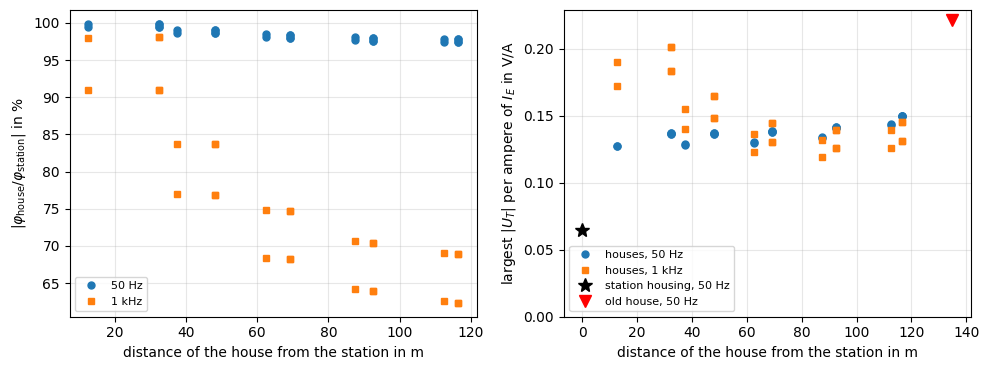

In [13]:
def centre(house):
    # Centre of a foundation: the mean of the vertices of its wires.
    wires = [e for e in world.electrodes if e.name in field.clusters[house]]
    return np.vstack([np.asarray(e.vertices)[:, :2] for e in wires]).mean(axis=0)


distance = np.array([np.hypot(*centre(h)) for h in HOUSES])
phi_station = field.electrode_potentials[STATION]
transfer, touch, old = {}, {}, {}
for k in (F50, F1K):
    phi_houses = np.array([field.electrode_potentials[h][k] for h in HOUSES])
    transfer[k] = np.abs(phi_houses / phi_station[k])
    touch[k] = touch_houses(field, world, k)
    old[k] = (
        abs(field.metadata["junction_potentials"]["old_house_box"][k]),
        touch_old_house(field, world, k),
    )

for k, label in ((F50, "50 Hz"), (F1K, "1 kHz")):
    print(
        f"{label}: house potentials {transfer[k].min():.1%} ... {transfer[k].max():.1%} of the station's; "
        f"U_T at the houses {touch[k].min():.3f} ... {touch[k].max():.3f} V/A, "
        f"largest {distance[np.argmax(touch[k])]:.0f} m from the station"
    )
    print(
        f"       old house: potential {old[k][0]:.3f} V/A, U_T {old[k][1]:.3f} V/A ({old[k][1] / old[k][0]:.0%} of it)"
    )
pe_b = SCENARIOS["B"][0] * abs(phi_station[F50]) * transfer[F50]
print(
    f"scenario B: protective conductors of the houses at {pe_b.min():.0f} ... {pe_b.max():.0f} V against remote earth"
)

fig, (ax_p, ax_t) = plt.subplots(1, 2, figsize=(10, 3.8))
for k, label, marker in ((F50, "50 Hz", "o"), (F1K, "1 kHz", "s")):
    ax_p.plot(distance, 100 * transfer[k], marker, ms=5, label=label)
    ax_t.plot(distance, touch[k], marker, ms=5, label=f"houses, {label}")
ax_t.plot(
    [0.0],
    [per_ampere["with the network"][1]],
    "k*",
    ms=10,
    label="station housing, 50 Hz",
)
ax_t.plot([135.0], [old[F50][1]], "rv", ms=8, label="old house, 50 Hz")
ax_p.set_ylabel(r"$|\varphi_\mathrm{house} / \varphi_\mathrm{station}|$ in %")
ax_t.set_ylabel(r"largest $|U_T|$ per ampere of $I_E$ in V/A")
for ax in (ax_p, ax_t):
    ax.set_xlabel("distance of the house from the station in m")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
ax_t.set_ylim(0, None)
fig.tight_layout()

In [14]:
assert transfer[F50].min() > 0.95  # at 50 Hz every house carries the EPR
assert transfer[F1K].min() < 0.7  # at 1 kHz the PEN decouples the far houses
assert old[F50][1] / old[F50][0] > 0.7  # no own electrode: mostly touch voltage
assert np.all(touch[F50] < 0.6 * transfer[F50] * abs(phi_station[F50]))  # about half

At 50 Hz every house carries 97 to 100 % of the station's potential: the
voltage drop along the PEN is small against the EPR. In scenario B the
protective conductor of every house rises to 280 to 287 V against remote
earth for the 0.5 s of the fault. The touch voltage at
a house with a foundation earth electrode is only about half of that
potential, 0.13 to 0.15 V/A, because its own electrode and its neighbours
lift the ground around it. It grows towards the edge of the network, where
fewer neighbours lift the ground; the largest is at a corner house, 116 m
from the station.

The old house at the end of the eastern cable has the potential of the
cabinet, 0.28 V/A, and 79 % of it appears as touch voltage: nothing lifts
the ground under it but the far field of the network. That is the classic
hazard of a transferred potential, and the foundation earth electrodes of
the other houses are what keeps it small there.

At 1 kHz the picture changes: the potentials fall along the PEN, to 62 %
at the far ends. What counts is the cable length from the station, not the
distance; the western main joins its first house 13.5 m from the station
ring, the eastern one after 3.5 m, hence the two branches near the
station. The houses close to the station now carry the higher 1 kHz EPR
and have the largest touch voltages, up to 0.20 V/A.

The surface potential at 50 Hz (per ampere of $I_E$) shows the whole
village lifted with the station: every foundation sits in its own
potential funnel on a common plateau.

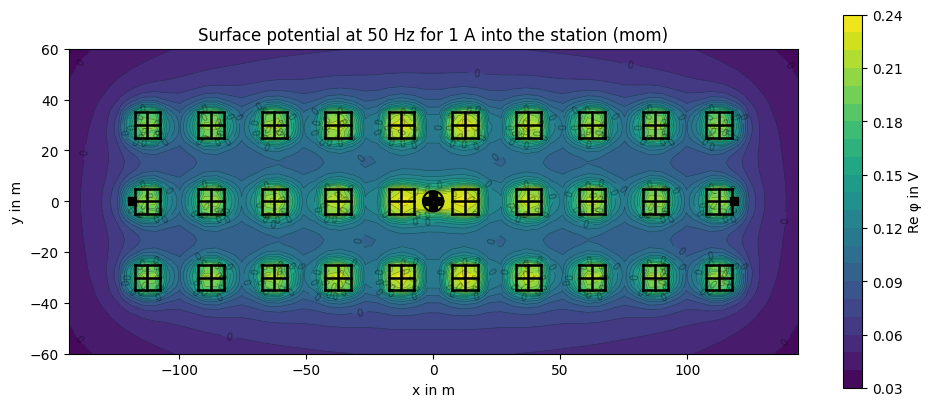

In [15]:
fig = gf.plot_surface_potential(
    field,
    world,
    frequency_index=F50,
    padding_m=25.0,
    n=60,
    levels=21,
    figsize=(10, 4.2),
    title="Surface potential at 50 Hz for 1 A into the station (mom)",
)

## 4 What changes at 1 kHz?

Below 1 kHz the soil stays quasi-static: an earth electrode is a
resistance. What changes with frequency is the PEN: its series impedance
$R + j\omega L$ grows with the angular frequency $\omega$, and the remote
houses contribute less (T04). This matters for the harmonics of a residual
earth-fault current, for earth testers that measure at a frequency other
than 50 Hz, and for the frequency-dependent model of the network that a
network calculation needs.

|Z_in|: 0.2908 Ohm at 50 Hz, 0.3961 Ohm at 1 kHz (+36%), angle 31 deg
station alone at 1 kHz: 9.901+0.000j Ohm (no inductive conductor)
split factor |s|: 1.75% at 50 Hz, 2.70% at 1 kHz
80 instead of 30 houses: |Z_in| x 0.47 at 50 Hz, x 0.62 at 1 kHz


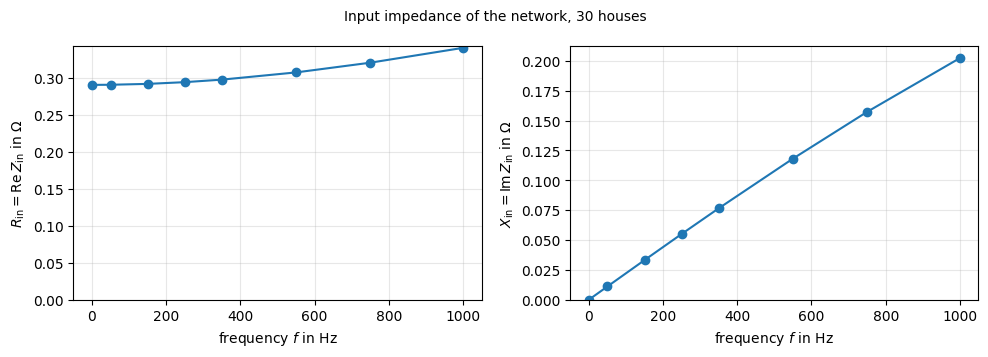

In [16]:
f = np.array(FREQUENCIES)
z_alone_f = np.array(result_alone.input_impedance())
print(
    f"|Z_in|: {abs(z_in[F50]):.4f} Ohm at 50 Hz, {abs(z_in[F1K]):.4f} Ohm at 1 kHz "
    f"({abs(z_in[F1K]) / abs(z_in[F50]) - 1:+.0%}), angle {np.degrees(np.angle(z_in[F1K])):.0f} deg"
)
print(f"station alone at 1 kHz: {z_alone_f[F1K]:.3f} Ohm (no inductive conductor)")
print(f"split factor |s|: {abs(s[F50]):.2%} at 50 Hz, {abs(s[F1K]):.2%} at 1 kHz")
gain_50, gain_1k = (abs(z_count[4, j] / z_count[3, j]) for j in (0, 1))
print(
    f"80 instead of 30 houses: |Z_in| x {gain_50:.2f} at 50 Hz, x {gain_1k:.2f} at 1 kHz"
)

fig, (ax_r, ax_x) = plt.subplots(1, 2, figsize=(10, 3.6))
ax_r.plot(f, z_in.real, "o-")
ax_x.plot(f, z_in.imag, "o-")
ax_r.set_ylabel(r"$R_\mathrm{in} = \mathrm{Re}\,Z_\mathrm{in}$ in $\Omega$")
ax_x.set_ylabel(r"$X_\mathrm{in} = \mathrm{Im}\,Z_\mathrm{in}$ in $\Omega$")
for ax in (ax_r, ax_x):
    ax.set_xlabel("frequency $f$ in Hz")
    ax.set_ylim(0, None)
    ax.grid(alpha=0.3)
fig.suptitle("Input impedance of the network, 30 houses", fontsize=10)
fig.tight_layout()

In [17]:
assert np.all(np.abs(z_alone_f - z_alone_f[0]) < 1e-12)  # no inductance
assert abs(z_in[0].imag) < 1e-12 and np.all(np.diff(z_in.imag) > 0)  # X rises with f
assert abs(z_in[F1K]) > 1.2 * abs(z_in[F50])
assert gain_1k > gain_50  # more houses help less at 1 kHz

From 50 Hz to 1 kHz the network impedance rises by 36 % to 0.40 Ω, at a
phase angle of 31°; the station alone stays at 9.9 Ω. The station's own
electrodes take a larger share of the current (2.7 % instead of 1.75 %),
and more houses help less: going from 30 to 80 houses lowers
$\lvert Z_\mathrm{in}\rvert$ to 0.47 of its value at 50 Hz but only to
0.62 at 1 kHz.

For a planner this means: an impedance measured or computed at 50 Hz is not
the impedance for the harmonics of a residual current; the touch voltage
per ampere of a 1 kHz current is up to 0.20 V/A here, a third more than at
50 Hz. The rho-f model of
[T04](../tutorials/T04_frequency_response_and_rho_f.ipynb) carries
$Z(f)$ into a network calculation. The earth-return model matters at these
frequencies: the default `sommerfeld` is the reference, while
`carson_series` reads the reactance of LV networks with short service drops
too high ([earth return](../explanation/earth-return.md)).

## 5 How far can the numbers be trusted?

Three free checks have already passed: Kirchhoff's current law (the
leakage currents add up to $I_E$), the fall of $Z_\mathrm{in}$ with every
added house, and `diagnose` without findings. Four more follow: the
discretisation, a second current model, a second Green's function, and a
method that shares no kernel with the others. The section ends with the
engines' known limits that apply here.

### Discretisation

The segment length is halved twice:

In [18]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    ladder = {
        ds: np.array(
            gf.create_engine(segment_length=ds, frequencies=[50.0, 1000.0])
            .solve(world)
            .input_impedance()
        )
        for ds in (2.0, 1.0, 0.5)
    }
for ds, z in ladder.items():
    change = np.abs(z / ladder[0.5] - 1.0)
    print(
        f"segments {ds:3.1f} m: Z_in = {z[0]:.5f} Ohm at 50 Hz, {z[1]:.5f} Ohm at 1 kHz; "
        f"against 0.5 m {change[0]:.1e} / {change[1]:.1e}"
    )
for w in caught:
    print(f"{w.category.__name__}: {str(w.message)[:100]} ...")

segments 2.0 m: Z_in = 0.29060+0.01109j Ohm at 50 Hz, 0.34051+0.20235j Ohm at 1 kHz; against 0.5 m 7.4e-05 / 1.3e-04
segments 1.0 m: Z_in = 0.29061+0.01109j Ohm at 50 Hz, 0.34051+0.20239j Ohm at 1 kHz; against 0.5 m 1.7e-05 / 3.0e-05
segments 0.5 m: Z_in = 0.29062+0.01109j Ohm at 50 Hz, 0.34052+0.20240j Ohm at 1 kHz; against 0.5 m 9.5e-19 / 2.6e-18


In [19]:
assert np.all(np.abs(ladder[1.0] / ladder[0.5] - 1.0) < 1e-3)

At 1 m segments the impedances are within 3e-5 of the 0.5 m values; even
2 m segments, at which the 1.5 m cabinet rods are a single segment (the
warning above), are within 1.3e-4.

### Current model and Green's function

`image` and `mom` share the image kernels but not the current model. `mom`
and `mom_sommerfeld` share the discretisation but not the Green's function:
the Tagg/Sunde image series against the Sommerfeld integral evaluated by
quadrature. The first pair runs on the full network; `mom_sommerfeld` is
slower, so it runs on a small variant with five houses.

In [20]:
z_mom = np.array(field.input_impedance())
dz = np.abs(z_in) / np.abs(z_mom) - 1.0
print(
    f"30 houses, |Z_in| image / mom - 1: {dz[F50]:+.2%} at 50 Hz, {dz[F1K]:+.2%} at 1 kHz"
)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", gf.UniformCurrentFieldWarning)
    touch_image = touch_houses(result, world)
du = touch_image / touch[F50] - 1.0
print(
    f"30 houses, U_T at the houses image / mom - 1: {du.min():+.1%} ... {du.max():+.1%}"
)
print(
    f"{len(caught)} x {caught[0].category.__name__}: {str(caught[0].message)[:140]} ..."
)

small = network(5)
small_z = {}
for backend in ("image", "mom", "mom_sommerfeld"):
    small_engine = gf.create_engine(
        backend=backend, segment_length=1.0, frequencies=[50.0, 1000.0]
    )
    small_z[backend] = np.array(small_engine.solve(small).input_impedance())
    print(
        f"5 houses, {backend:14s}: Z_in = {small_z[backend][0]:.5f} / {small_z[backend][1]:.5f} Ohm at 50 Hz / 1 kHz"
    )
kernel_gap = np.max(np.abs(small_z["mom_sommerfeld"] / small_z["mom"] - 1.0))
print(f"mom_sommerfeld against mom: {kernel_gap:.1e}")

30 houses, |Z_in| image / mom - 1: +1.15% at 50 Hz, +0.65% at 1 kHz


30 houses, U_T at the houses image / mom - 1: +3.1% ... +3.4%
30 x UniformCurrentFieldWarning: touch_voltage_envelope: uniform-current backend 'image_2layer' within 5 m of a grid, mesh, star, strip, open polyline or bonded multi-electr ...
5 houses, image         : Z_in = 1.28680+0.02112j / 1.34282+0.40240j Ohm at 50 Hz / 1 kHz


5 houses, mom           : Z_in = 1.26913+0.02115j / 1.32579+0.40268j Ohm at 50 Hz / 1 kHz


5 houses, mom_sommerfeld: Z_in = 1.26913+0.02115j / 1.32579+0.40268j Ohm at 50 Hz / 1 kHz
mom_sommerfeld against mom: 1.1e-08


In [21]:
assert np.all(np.abs(dz[[F50, F1K]]) < 0.03)  # two current models: about 1 %
assert np.all(np.abs(du) < 0.1)
assert kernel_gap < 1e-4  # two Green's functions, one discretisation

The two current models differ by 1.2 % at 50 Hz and 0.7 % at 1 kHz; the
`fem` check below shows that most of it is the point kernel of `mom`,
which reads 1 to 2 % low. At the houses the `image` touch voltages lie
about 3 % above the `mom` values, and every call warns that they are
impedance-grade: near meshes and bonded clusters `mom` is the field-grade
engine. The two Green's functions agree to about 1e-8: the image series is
right for this soil.

### What `fem` can and cannot do here

`fem` solves the volume problem by finite elements and shares no kernel
with the integral engines ([fem](../explanation/engines/fem.md)). Its
axisymmetric model takes rods on one axis and rings around it, to about
1e-4, in a fraction of a second. The station's ring alone is such a world:

In [22]:
def ring_alone():
    ring = gf.create_world(soil=SOIL.to_soil(np.random.default_rng(0)))
    gf.create_electrode(
        ring, "ring", name="ring", center=(0.0, 0.0, 0.6), radius=4.0, wire_radius=0.005
    )
    gf.create_source(ring, attached_to="ring", magnitude=1.0)
    return ring


with warnings.catch_warnings():
    warnings.simplefilter("ignore", gf.ExperimentalBackendWarning)
    ring_fem = gf.create_engine(backend="fem", segment_length=0.5).solve(ring_alone())
r_fem = ring_fem.input_impedance()[0].real
print(
    f"station ring alone: fem   {r_fem:.4f} Ohm (error estimate {ring_fem.metadata['fem_error_estimate']:.1e})"
)
r_ring = {}
for backend in ("image", "mom"):
    ring_result = gf.create_engine(backend=backend, segment_length=0.5).solve(
        ring_alone()
    )
    r_ring[backend] = ring_result.input_impedance()[0].real
    print(
        f"                    {backend:5s} {r_ring[backend]:.4f} Ohm ({r_ring[backend] / r_fem - 1:+.2%} against fem)"
    )

try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", gf.ExperimentalBackendWarning)
        gf.create_engine(backend="fem", segment_length=1.0).solve(network())
except gf.ResourceLimitError as error:  # the port limit of the 3-D model
    refusal = str(error)
except ImportError as error:  # the 3-D model needs the optional fem3d extra
    refusal = str(error)
print("the network with fem:", refusal.split("). ")[0] + ").")

station ring alone: fem   12.2142 Ohm (error estimate 1.4e-03)
                    image 12.2049 Ohm (-0.08% against fem)
                    mom   12.0677 Ohm (-1.20% against fem)


the network with fem: Backend 'fem': the three-dimensional model would solve 187 ports, above its limit of 100 ports (FemOptions.max_ports_3d; every electrode and every leaking piece of a galvanic distributed conductor is a port, and every port one conjugate-gradient solve per mesh level: about 920 minutes at the predicted 92490608 nodes of the finer mesh).


In [23]:
assert abs(r_ring["image"] / r_fem - 1.0) < 0.005  # one current is exact for a ring
assert -0.03 < r_ring["mom"] / r_fem - 1.0 < 0.0  # the point kernel of mom reads low
assert "187 ports" in refusal or "fem3d" in refusal

On the ring `image` lies within 0.1 % of `fem` (whose error estimate is
1.4e-3), `mom` 1.2 % below it, the pattern of the
[validation page](../explanation/validation.md). The station with its four
rods off the axis needs the three-dimensional model; for a station earth of
similar size (the AP1 station of the validation, a 4 m × 4 m ring with three
4 m rods) the fem page reports 75 to 140 s and about 4.3 GB, more than this
example may spend. The network is refused before any mesh is built: 187
ports against a limit of 100, with a predicted solve time of 920 minutes
(without the optional `fem3d` extra the call stops earlier, with an
`ImportError` that names the extra). `fem` is a reference for single
earthing systems, not a network engine.

### Known limits of the engines that apply here

From the [known limitations](../reference/known-limitations.md), the ones
that bear on this example:

- **Uniform current per wire** (`image`): impedances of meshes like these
  foundations are 0.4 to 0.7 % above one current per segment;
  touch and step voltages next to them are only impedance-grade, hence
  `mom` for the field values here.
- **Point kernel** (`mom`): grounding resistances 0.9 to 1.9 % low, as
  measured above.
- **Earth return**: `carson_series` reads the reactance of generated LV
  networks 4 to 21 % high at 1 kHz against `sommerfeld`; use the default.
- **Generated networks**: the service drops of the outer rows pass 0.2 m
  above the side wires of the centre-row houses without inductive coupling
  to them (moved aside, at most 0.006 % with an insulated PEN); the 1 kHz
  reactance depends on where cables and drops meet the foundations; and the
  star topology with one cabinet per building group is a modelling choice:
  for the default 30-house network it reads a reactance at 1 kHz 55 to 64 %
  above that of the former cabinet strip with its parallel drops.
- **Quasi-static soil**: valid below 1 kHz; impulse and lightning currents
  are out of scope.

## Summary

- **Global earthing.** The 30-house network lowers the impedance at the
  station from 9.9 Ω (the station alone) to 0.29 Ω at 50 Hz, 2.9 %; 98 % of
  the fault current leaves the soil at the houses. In five soils of the AP1
  grid the ratio is 2.3 to 14 %; the network impedance follows the bottom
  layer.
- **Earth fault.** With the network the EPR is 0.29 V/A; the touch
  voltages are 0.065 V/A at the station housing and at most 0.15 V/A at the
  houses with a foundation earth electrode. Scenario A (60 A, not cleared):
  at most 13 V against 80 V, where the station alone would give 216 V.
  Scenario B (1 kA, 0.5 s): 221 V against 225 V, at the old house.
- **Transferred potentials.** At 50 Hz every house carries 97 to 100 % of
  the station's potential. A foundation earth electrode keeps the touch
  voltage at about half of it; at a house without one it is 79 %.
- **1 kHz.** $\lvert Z_\mathrm{in}\rvert$ rises by 36 %, the far houses fall to
  62 % of the station's potential, more houses help less, and the touch
  voltage per ampere near the station rises by a third.
- **Trust.** 1 m segments are converged to 3e-5; `image` and `mom` agree
  within 1.2 % on the impedance and 3.4 % on the touch voltages; two Green's
  functions agree to 1e-8; `fem` confirms the station ring to 0.1 % and
  refuses the network.

## Limits of this example

- **One generated network.** The generator's defaults in one soil, one
  realisation: not a real network. A study runs the parameter space
  (house counts, penetration of foundation earth electrodes, soils) with
  sweeps or Monte Carlo (how-to guide
  [Sweeps and Monte Carlo](../how-to/sweeps-and-monte-carlo.md)).
- **Bare foundations.** The concrete encasement of real foundation earth
  electrodes changes their resistance (case study E02 and the
  [concrete shells](../explanation/concrete-shells.md) page).
- **The MV side is not modelled.** No MV cable screens, no neighbouring
  stations connected through them, no reduction factor: $I_E$ is an input.
  In a real network the cable screens connect further station earths and
  lower the impedance further.
- **Only this LV network.** Water pipes, other utilities, neighbouring LV
  networks and the houses' own installations are not part of the model.
- **Touch voltages are prospective proxies.** Feet 1 m from the station
  walls and the house foundations stand for the real touch points; no body,
  shoe or surface-layer resistance is included. Step voltages are not
  assessed ([T08](../tutorials/T08_touch_and_step_assessment.ipynb) shows
  how), nor are the stress voltages on the LV installations.
- **EN 50522** enters only through the library's permissible touch voltage
  curve; the scenario currents are examples.